# FI4008 Assessment 1: ML trading strategy on SPY

This notebook runs the full analysis and then shows the main results. The code itself is in seven Python files in the main project folder, and the first code cell below just runs `main.py`:

| File | What it does |
|---|---|
| `main.py` | Runs every step in order |
| `data.py` | Loads the downloaded data, checks it hasn't changed, cleans it and works out the descriptive stats |
| `features.py` | Builds the target (is tomorrow an up day?) and the 37 predictors, plus the look-ahead tests |
| `models.py` | The three models, the time-series tuning and the year-by-year (walk-forward) predictions |
| `backtest.py` | The trading rule, costs, benchmarks and the robustness versions |
| `evaluation.py` | Prediction metrics, significance tests, and the placebo / positive control checks |
| `plots.py` | All 13 figures |

Running it rebuilds every table in `tables/` and every figure in `figures/`. It takes about 7 minutes, mostly because of the model tuning.

In [ ]:
# Installing exact versions from requirements.txt doesnt work in jupyter, this line installs the packages needed directly.
%pip install numpy pandas scipy scikit-learn matplotlib

In [1]:
import os
# main.py has to be in the working folder. If this notebook is in notebooks/, move up one level first.
if not os.path.exists("main.py"):
    os.chdir("..")
%run main.py

Python 3.13.16 | numpy 2.5.3 | pandas 3.0.5 | scipy 1.18.1 | scikit-learn 1.9.1 | matplotlib 3.11.2

--- 1. Data ---
All 18 raw files verified (downloaded 2026-10-22T16:43:01+00:00)


FRED blanks (bond-market holidays): {'DGS3MO': 233, 'DGS2': 233, 'DGS10': 233, 'T10Y2Y': 233, 'T10Y3M': 233}
Sample end date: 2026-10-21
5485 trading days; unscheduled closures: [datetime.date(2007, 1, 2), datetime.date(2012, 10, 29), datetime.date(2012, 10, 30), datetime.date(2018, 12, 5), datetime.date(2025, 1, 9)]
VIX rows on non-trading days (dropped): [datetime.date(2026, 5, 25), datetime.date(2026, 9, 7)]
SPY total return 10.91% a year, price return 8.91%, dividends 2.00%
|z| > 4: observed 40 days, normal distribution would give 0.35


Training period only: absolute-return AC outside band at 20 of 20 lags (smallest 0.24); lag-1 return AC -0.081
                      Days  Up days (%)  Ann. return (%)  Ann. vol (%)  Max drawdown (%)
Train (to 2016)       3020         54.8              7.5          19.5             -55.2
Validation (2017-19)   754         56.5             15.1          12.8             -19.3
Test (2020-)          1710         54.7             15.4          20.0             -33.7


Median daily dollar volume: $23.1bn



--- 2. Features ---
Modelling table: 5232 days x 37 predictors, 2006-01-03 to 2026-10-20


Truncation test passed on 14 dates: no predictor uses future data
Target alignment test passed: target(t) equals the realised return of day t+1
Largest absolute correlation with next-day return: 0.064 (rsi_14)
16 of 666 predictor pairs have |correlation| > 0.8


... (9 outputs left out)


--- 7. Robustness ---


                                   0 bps  5 bps  10 bps  20 bps  Turnover (x per year)
Logistic regression                 0.53   0.49    0.44    0.35                  16.96
Random forest                       0.62   0.55    0.48    0.33                  26.98
Gradient boosting                   0.73   0.54    0.34   -0.04                  64.14
Buy-and-hold                        0.66   0.66    0.66    0.66                   0.15
SMA 50/200 crossover                0.51   0.50    0.50    0.49                   1.03
Vol-managed SPY                     0.74   0.73    0.72    0.70                   2.45
Logistic regression + vol-managed   0.69   0.64    0.58    0.48                  14.21 
                          Long/cash (main)                                          Long/short                                       One-day delay                                       5-day horizon  \
                    Annualised return (%) Sharpe ratio Max drawdown (%) Annualised return (%) Sharpe 

                                   Sharpe difference vs buy-and-hold  95% CI lower  95% CI upper  Share of resamples above 0 (%)
Logistic regression                                           -0.219        -0.434        -0.011                            2.05
Random forest                                                 -0.184        -0.413         0.041                            5.25
Gradient boosting                                             -0.317        -0.841         0.145                            9.15
SMA 50/200 crossover                                          -0.162        -0.549         0.293                           24.35
Vol-managed SPY                                                0.059        -0.215         0.318                           59.60
Logistic regression + vol-managed                             -0.076        -0.411         0.222                           27.55


Trials: 38 configurations
                                                    Test Sharpe after costs  Luck benchmark (expected max Sharpe of skill-less trials)  Deflated Sharpe ratio (%)  Probability Sharpe > 0 (%)
Logistic regression                                                   0.442                                              0.984                              8.124                      87.278
Logistic regression + vol-managed                                     0.585                                              0.984                             15.166                      93.436
Vol-managed SPY                                                       0.720                                              0.984                             24.825                      96.802
Buy-and-hold                                                          0.661                                              0.984                             20.231                      95.610
Logistic regression (val

## Key results
### How well the models predicted direction, test period 2020-2026

In [2]:
import pandas as pd
from IPython.display import Image, display
pd.read_csv("tables/T17_test_predictive.csv", index_col=0).round(3)

,Accuracy,Always-up accuracy,Precision (up),Recall (up),F1 (up),ROC-AUC,Log loss,Predicted up (%),PT statistic,PT p-value
Logistic regression,0.542,0.547,0.548,0.942,0.693,0.503,0.691,94.149,0.147,0.442
Random forest,0.535,0.547,0.549,0.852,0.668,0.512,0.690,85.020,0.280,0.390
Gradient boosting,0.531,0.547,0.554,0.724,0.628,0.524,0.695,71.445,0.967,0.167
Always up (benchmark),0.547,0.547,0.547,1.000,0.707,0.500,NaN,100.000,NaN,NaN


### Returns and Sharpe ratios before and after 10 bps costs, test period

In [3]:
pd.read_csv("tables/T19_test_backtest.csv", index_col=0, header=[0, 1])

Before costs                                       After 10 bps costs                                                                                \
                                  Cumulative return (%) Annualised return (%) Sharpe ratio Cumulative return (%) Annualised return (%) Annualised volatility (%) Sharpe ratio Max drawdown (%)   
Logistic regression                              113.44                 11.83         0.53                 90.24                  9.95                     18.73         0.44           -34.61   
Random forest                                    137.48                 13.60         0.62                 97.76                 10.58                     18.46         0.48           -34.55   
Gradient boosting                                153.70                 14.71         0.73                 64.19                  7.59                     16.60         0.34           -27.65   
Buy-and-hold                                     161.72                 15.24         0.66                161.45                 15.22                     19.98         0.66           -33.72   
SMA 50/200 crossover                              97.45                 10.55         0.51                 96.07                 10.44                     16.76         0.50           -33.72   
Vol-managed SPY                                  134.01                 13.36         0.74                130.16                 13.08                     14.41         0.72           -20.97   
Logistic regression + vol-managed                120.38                 12.36         0.69                100.13                 10.77                     14.13         0.58           -20.39   

                                                                                                       
                                  Turnover (x per year) Trades Time in SPY (%) Average SPY weight (%)  
Logistic regression                               16.96  115.0           94.15                  94.15  
Random forest                                     26.98  183.0           85.02                  85.02  
Gradient boosting                                 64.14  435.0           71.45                  71.45  
Buy-and-hold                                       0.15    1.0          100.00                 100.00  
SMA 50/200 crossover                               1.03    7.0           80.57                  80.57  
Vol-managed SPY                                    2.45  143.0          100.00                  90.37  
Logistic regression + vol-managed                 14.21  244.0           94.15                  86.26

### Growth of $1 and drawdowns, test period

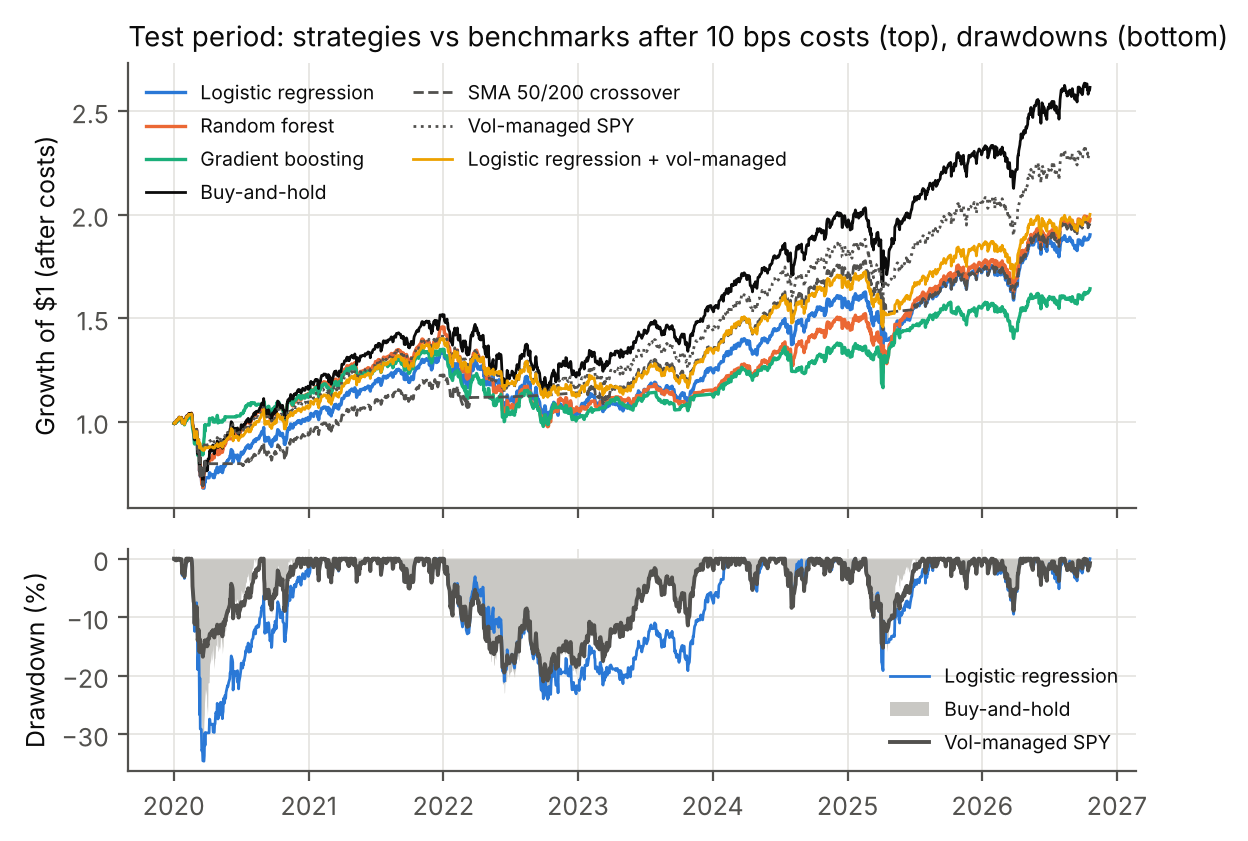

In [4]:
display(Image("figures/F12_test_equity.png", width=700))

### Does the most accurate model make the most money?

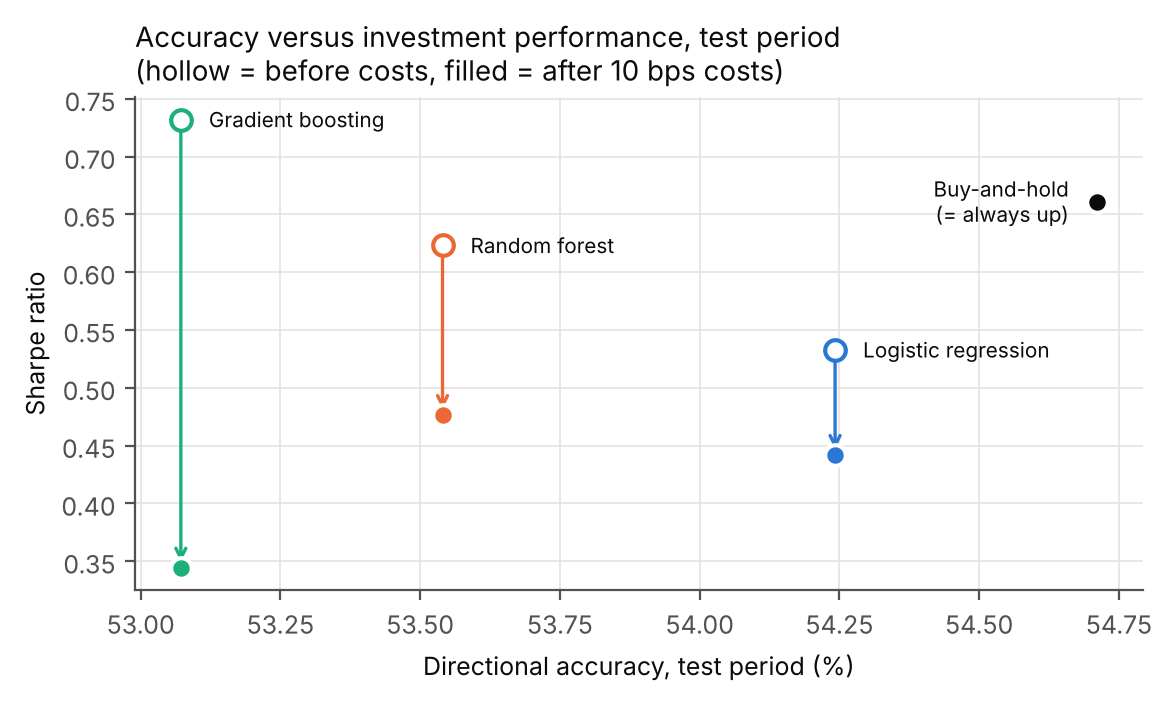

In [5]:
display(Image("figures/F13_accuracy_vs_sharpe.png", width=700))

### Could the gap to buy-and-hold just be luck? Block bootstrap and deflated Sharpe ratio

In [6]:
display(pd.read_csv("tables/T25_bootstrap_sharpe.csv", index_col=0))
pd.read_csv("tables/T26_deflated_sharpe.csv", index_col=0)

,Sharpe difference vs buy-and-hold,95% CI lower,95% CI upper,Share of resamples above 0 (%)
Logistic regression,-0.219,-0.434,-0.011,2.05
Random forest,-0.184,-0.413,0.041,5.25
Gradient boosting,-0.317,-0.841,0.145,9.15
SMA 50/200 crossover,-0.162,-0.549,0.293,24.35
Vol-managed SPY,0.059,-0.215,0.318,59.60
Logistic regression + vol-managed,-0.076,-0.411,0.222,27.55


,Test Sharpe after costs,Luck benchmark (expected max Sharpe of skill-less trials),Deflated Sharpe ratio (%),Probability Sharpe > 0 (%)
Logistic regression,0.442,0.984,8.124,87.278
Logistic regression + vol-managed,0.585,0.984,15.166,93.436
Vol-managed SPY,0.720,0.984,24.825,96.802
Buy-and-hold,0.661,0.984,20.231,95.610
"Logistic regression (validation period, where it was selected)",NaN,0.984,41.331,NaN
